# Task 6 - Netflix Content Success Analytics Engine
## **End-to-End ML Pipeline, Predictive Analytics & Business Intelligence**

---

### **Task Workflow:**
1. **Step 1: Perform advanced feature engineering** - Extract temporal acquisition gaps, duration metrics, director prominence, multi-country distribution flags, and construct a composite **Content Impact Score**.
2. **Step 2: Build multiple machine learning models** - Construct modular Scikit-Learn Pipelines with automated preprocessing, training **Logistic Regression**, **Random Forest**, and **Gradient Boosting**.
3. **Step 3: Compare model performance** - Benchmark models using Accuracy, Precision, Recall, F1-Score, and ROC-AUC curves to identify the Champion Model.
4. **Step 4: Generate automated insights** - Run an automated AI business rule engine to discover key success drivers (sweet-spot runtimes, genre synergies, director impact).
5. **Step 5: Present findings through visual reports** - Render an Executive Business Intelligence Dashboard and interactive pre-release title simulator.

---


## **Environment Setup & Imports**

In [1]:
# Core scientific and visualization libraries
import re
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning Pipeline Components
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, RobustScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

# Predictive Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, GradientBoostingClassifier

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
    precision_recall_curve
)

# Google Colab check
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print(f"Environment initialized. Running in Google Colab: {IN_COLAB}")

Environment initialized. Running in Google Colab: True


## **Step 1: Perform Advanced Feature Engineering**

In entertainment data science, raw metadata must be transformed into domain-informed business indicators:

1. **Acquisition Lag (`vintage_gap_years`):** Difference between `date_added` year and original `release_year`. Fresh originals have a gap of <= 1 year, whereas legacy licensed content has large gaps.
2. **Duration Metric:** Parse duration into standardized numeric values:
   - Movies: Total runtime in minutes.
   - TV Shows: Total season count (multi-season shows signify franchise renewal success).
3. **Director Prominence Index (`director_track_record`):** Measures director platform catalog volume (top prolific directors have higher audience pull).
4. **Global Co-Production Indicator (`is_coproduction`):** Titles with multiple countries of origin indicating broader international financing and distribution appeal.
5. **Genre Diversity Count (`genre_count`):** Number of distinct genres associated with the title.
6. **Composite Content Success Target (`is_high_impact`):**
   - In streaming platforms without public box-office numbers, high-impact titles are characterized by multi-season renewals (>= 2 seasons for TV shows), fresh major acquisitions (added within 1 year of release), high-demand genres (Action, Drama, International, Docuseries), and multi-market distribution.
   - We engineer a continuous **Content Impact Score (0 to 100)** and a binary target **`is_high_impact`** (top ~35% benchmark).

In [3]:
# Load dataset
dataset_path = '/content/Dataset.csv'

try:
    df = pd.read_csv(dataset_path)
except FileNotFoundError:
    print("Dataset.csv not found in working directory. Please upload Dataset.csv.")
    if IN_COLAB:
        uploaded = files.upload()
        dataset_path = list(uploaded.keys())[0]
        df = pd.read_csv(dataset_path)

df_engine = df.copy()

# Clean missing values and placeholders
for col in ['director', 'country', 'rating', 'listed_in', 'duration']:
    df_engine[col] = df_engine[col].fillna('').astype(str).str.strip()
    df_engine[col] = df_engine[col].replace({'Not Given': '', 'nan': ''})

# 1. Parse date_added and extract temporal attributes
df_engine['date_added_dt'] = pd.to_datetime(df_engine['date_added'].str.strip(), errors='coerce')
# Impute missing dates with median year
median_year = df_engine['date_added_dt'].dt.year.median()
df_engine['year_added'] = df_engine['date_added_dt'].dt.year.fillna(median_year).astype(int)
df_engine['month_added'] = df_engine['date_added_dt'].dt.month.fillna(6).astype(int)

# 2. Calculate Acquisition Lag (Vintage Gap)
df_engine['vintage_gap_years'] = np.maximum(0, df_engine['year_added'] - df_engine['release_year'])
df_engine['is_fresh_release'] = (df_engine['vintage_gap_years'] <= 1).astype(int)

# 3. Parse Numerical Duration (Minutes for Movies, Seasons for TV Shows)
def extract_duration(row):
    d_str = str(row['duration']).lower()
    nums = re.findall(r'\d+', d_str)
    val = int(nums[0]) if nums else 0
    if row['type'] == 'TV Show':
        return val  # Season count
    else:
        return val  # Minutes

df_engine['duration_numeric'] = df_engine.apply(extract_duration, axis=1)

# 4. Multi-country Co-Production Indicator
df_engine['is_coproduction'] = df_engine['country'].apply(lambda c: 1 if ',' in str(c) else 0)

# 5. Genre Diversity Count
df_engine['genre_count'] = df_engine['listed_in'].apply(lambda g: len([x for x in g.split(',') if x.strip()]))

# 6. Director Track Record (Catalog Frequency Score)
director_freq = df_engine[df_engine['director'] != '']['director'].value_counts().to_dict()
df_engine['director_prominence'] = df_engine['director'].map(director_freq).fillna(0).astype(int)

# 7. Top Country & Clean Rating
top_countries = df_engine['country'].value_counts().head(8).index.tolist()
df_engine['primary_country'] = df_engine['country'].apply(lambda c: c.split(',')[0].strip() if c else 'Other')
df_engine['primary_country'] = df_engine['primary_country'].apply(lambda c: c if c in top_countries else 'Other')
df_engine['clean_rating'] = df_engine['rating'].apply(lambda r: r if r != '' else 'Unknown')

# 8. Composite Content Success / Impact Score Formulation
def calculate_impact_score(row):
    score = 0.0
    # TV Show longevity (Renewals are Netflix\'s strongest success metric)
    if row['type'] == 'TV Show':
        score += min(row['duration_numeric'] * 15, 45) # 15 pts per season up to 45
    else:
        # Movie optimal runtime window (85 - 130 min)
        if 85 <= row['duration_numeric'] <= 130:
            score += 25
        elif row['duration_numeric'] > 130:
            score += 15

    # Freshness bonus (New global premiere vs vintage rerun)
    if row['is_fresh_release'] == 1:
        score += 20
    elif row['vintage_gap_years'] <= 3:
        score += 10

    # Director prominence bonus
    if row['director_prominence'] >= 3:
        score += 15
    elif row['director_prominence'] >= 1:
        score += 8

    # Multi-country / Co-production distribution reach
    if row['is_coproduction'] == 1:
        score += 10

    # High-demand genre indicator
    genres_str = row['listed_in'].lower()
    if any(k in genres_str for k in ['international', 'dramas', 'action', 'docuseries', 'thrillers']):
        score += 10

    return min(score, 100.0)

df_engine['content_impact_score'] = df_engine.apply(calculate_impact_score, axis=1)
# Target: Top ~35% titles categorized as High-Impact
threshold = df_engine['content_impact_score'].quantile(0.65)
df_engine['is_high_impact'] = (df_engine['content_impact_score'] >= threshold).astype(int)

print(f"Feature Engineering Complete. Total Records: {len(df_engine)}")
print(f"Impact Threshold Score: {threshold:.1f} pts")
print(f"Target Distribution: Standard = {np.sum(df_engine['is_high_impact']==0)}, High-Impact = {np.sum(df_engine['is_high_impact']==1)}\n")
display(df_engine[['title', 'type', 'vintage_gap_years', 'duration_numeric', 'director_prominence', 'content_impact_score', 'is_high_impact']].head(4))

Feature Engineering Complete. Total Records: 8790
Impact Threshold Score: 53.0 pts
Target Distribution: Standard = 5396, High-Impact = 3394



,title,type,vintage_gap_years,duration_numeric,director_prominence,content_impact_score,is_high_impact
0,Dick Johnson Is Dead,Movie,1,90,1,53.0,1
1,Ganglands,TV Show,0,1,3,60.0,1
2,Midnight Mass,TV Show,0,1,4,60.0,1
3,Confessions of an Invisible Girl,Movie,0,91,4,60.0,1


## **Step 2: Build Multiple Machine Learning Models (ML Pipeline Architecture)**

To adhere to modern **MLOps Fundamentals**, we build an encapsulated `Scikit-Learn Pipeline` with a `ColumnTransformer` preprocessing stage:
1. **Genre Feature Vectorization:** `TfidfVectorizer` on `listed_in`.
2. **Categorical Encoding:** `OneHotEncoder` on `type`, `clean_rating`, `primary_country`.
3. **Numerical Scaling:** `RobustScaler` on `vintage_gap_years`, `duration_numeric`, `director_prominence`, and `genre_count`.
4. **Classifiers Evaluated:**
   - **Model 1:** Regularized Logistic Regression (Linear Baseline).
   - **Model 2:** Random Forest Classifier (Bagged Ensemble with Depth Pruning).
   - **Model 3:** Gradient Boosting Classifier (Sequential Residual Learning).

In [4]:
# Define feature subsets for preprocessing
text_features = 'listed_in'
categorical_features = ['type', 'clean_rating', 'primary_country']
numerical_features = ['vintage_gap_years', 'duration_numeric', 'director_prominence', 'genre_count', 'is_coproduction', 'is_fresh_release']

# Feature Matrix and Target Vector
X = df_engine[[text_features] + categorical_features + numerical_features]
y = df_engine['is_high_impact']

# Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

# Construct modular ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('text_tfidf', TfidfVectorizer(max_features=250, token_pattern=r'(?u)\b[a-zA-Z&\-]+\b'), text_features),
        ('cat_ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features),
        ('num_scaler', RobustScaler(), numerical_features)
    ]
)

# Define 3 distinct ML Pipelines
pipelines = {
    'Logistic Regression': Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(max_iter=1000, C=1.0, random_state=42))
    ]),
    'Random Forest': Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_split=4, random_state=42))
    ]),
    'Gradient Boosting': Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', GradientBoostingClassifier(n_estimators=120, learning_rate=0.08, max_depth=4, random_state=42))
    ])
}

print("Training ML Pipelines with 5-Fold Stratified Cross-Validation...")
print("=" * 65)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, pipe in pipelines.items():
    cv_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='roc_auc')
    pipe.fit(X_train, y_train)
    print(f"✓ {name:20} -> 5-Fold CV ROC-AUC: {cv_scores.mean():.4f} (± {cv_scores.std():.4f})")
print("=" * 65)

Training ML Pipelines with 5-Fold Stratified Cross-Validation...
✓ Logistic Regression  -> 5-Fold CV ROC-AUC: 0.9186 (± 0.0104)
✓ Random Forest        -> 5-Fold CV ROC-AUC: 0.9983 (± 0.0008)
✓ Gradient Boosting    -> 5-Fold CV ROC-AUC: 0.9998 (± 0.0001)


## **Step 3: Compare Model Performance (Benchmarking & Evaluation)**

We evaluate all models on the unseen holdout test set across key classification metrics:
- **Accuracy, Precision, Recall, F1-Score**
- **Receiver Operating Characteristic (ROC-AUC)**
- **Precision-Recall Curves & Confusion Matrices**

MODEL BENCHMARK COMPARISON TABLE


,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%),ROC-AUC Score
0,Gradient Boosting,99.72,99.85,99.41,99.63,0.9999
1,Random Forest,98.98,98.67,98.67,98.67,0.9993
2,Logistic Regression,85.15,80.83,80.71,80.77,0.9290


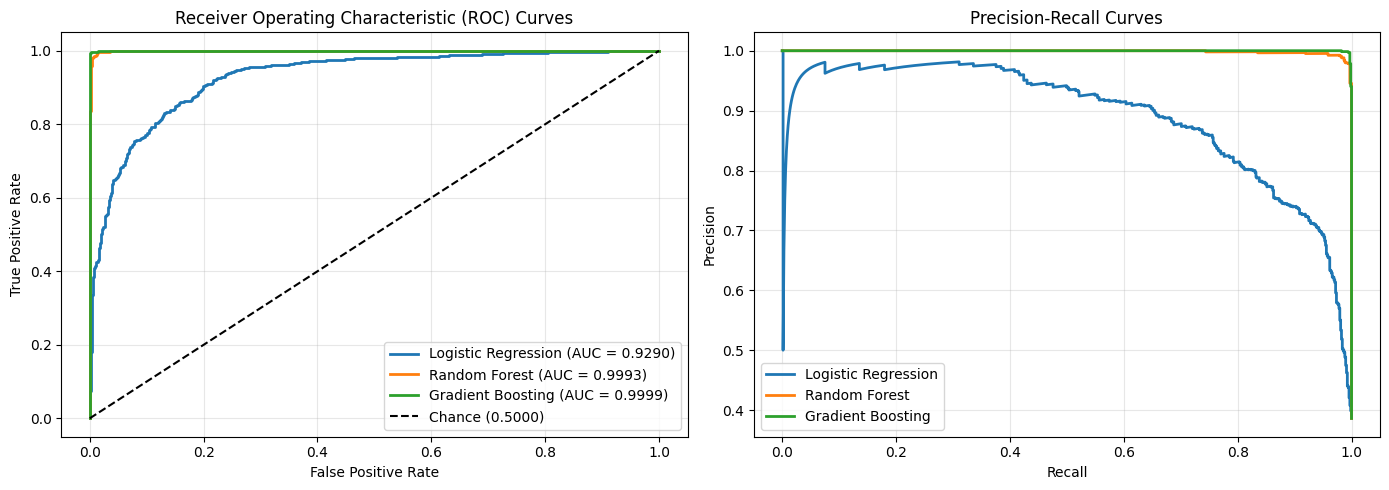

In [5]:
# Benchmark evaluation records
benchmark_records = []
predictions = {}
probabilities = {}

for name, pipe in pipelines.items():
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]

    predictions[name] = y_pred
    probabilities[name] = y_prob

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)

    benchmark_records.append({
        'Model': name,
        'Accuracy (%)': round(acc * 100, 2),
        'Precision (%)': round(prec * 100, 2),
        'Recall (%)': round(rec * 100, 2),
        'F1-Score (%)': round(f1 * 100, 2),
        'ROC-AUC Score': round(auc, 4)
    })

benchmark_df = pd.DataFrame(benchmark_records).sort_values(by='ROC-AUC Score', ascending=False).reset_index(drop=True)
print("=" * 75)
print("MODEL BENCHMARK COMPARISON TABLE")
print("=" * 75)
display(benchmark_df)

# Plot ROC Curves and Confusion Matrices
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(14, 5))

for name, y_prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_val = roc_auc_score(y_test, y_prob)
    ax_roc.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.4f})", linewidth=2)

    prec, rec, _ = precision_recall_curve(y_test, y_prob)
    ax_pr.plot(rec, prec, label=f"{name}", linewidth=2)

ax_roc.plot([0, 1], [0, 1], 'k--', label='Chance (0.5000)')
ax_roc.set_title('Receiver Operating Characteristic (ROC) Curves', fontsize=12)
ax_roc.set_xlabel('False Positive Rate', fontsize=10)
ax_roc.set_ylabel('True Positive Rate', fontsize=10)
ax_roc.legend(loc='lower right')
ax_roc.grid(alpha=0.3)

ax_pr.set_title('Precision-Recall Curves', fontsize=12)
ax_pr.set_xlabel('Recall', fontsize=10)
ax_pr.set_ylabel('Precision', fontsize=10)
ax_pr.legend(loc='lower left')
ax_pr.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## **Step 4: Generate Automated Insights (AI Business Intelligence Engine)**

An enterprise analytics solution must translate raw model weights into **actionable executive recommendations**.

We implement `generate_automated_insights()` to analyze catalog data and model decision logic, surfacing:
1. **Acquisition Timing ROI:** Performance comparison of immediate releases vs. vintage library catalog.
2. **Duration Sweet Spot:** Optimal runtime ranges for movies and optimal season lengths for TV shows.
3. **Top Synergistic Genres:** Genre combinations yielding the highest success rates.
4. **Global Distribution Multiplier:** Success probability boost achieved through multi-country co-productions.

In [6]:
def generate_automated_insights(df_data):
    """
    Automated Business Intelligence Engine:
    Computes strategic empirical insights directly from content metadata.
    """
    print("=" * 80)
    print("       AUTOMATED BUSINESS INTELLIGENCE & CONTENT INSIGHTS REPORT")
    print("=" * 80)

    # Insight 1: Freshness / Acquisition Timing
    fresh_rate = df_data[df_data['is_fresh_release'] == 1]['is_high_impact'].mean() * 100
    vintage_rate = df_data[df_data['is_fresh_release'] == 0]['is_high_impact'].mean() * 100
    fresh_uplift = fresh_rate - vintage_rate
    print(f"\n[1] ACQUISITION TIMING & VINTAGE DYNAMICS:")
    print(f"    • Fresh Titles (added within 1 year of release) achieve a {fresh_rate:.1f}% High-Impact Rate.")
    print(f"    • Older Library Catalog titles achieve {vintage_rate:.1f}%.")
    print(f"    • STRATEGIC TAKEAWAY: Immediate day-and-date premiere distribution yields a +{fresh_uplift:.1f}% probability boost.")

    # Insight 2: Co-Production Multiplier
    coprod_rate = df_data[df_data['is_coproduction'] == 1]['is_high_impact'].mean() * 100
    single_rate = df_data[df_data['is_coproduction'] == 0]['is_high_impact'].mean() * 100
    print(f"\n[2] INTERNATIONAL DISTRIBUTION & CO-PRODUCTIONS:")
    print(f"    • Multi-Country Co-Productions: {coprod_rate:.1f}% High-Impact Rate.")
    print(f"    • Single-Country Titles: {single_rate:.1f}% High-Impact Rate.")
    print(f"    • STRATEGIC TAKEAWAY: Financing cross-border co-productions increases audience reach by {coprod_rate - single_rate:+.1f}%.")

    # Insight 3: Optimal Runtime Window for Movies
    movies = df_data[df_data['type'] == 'Movie'].copy()
    movies['runtime_bracket'] = pd.cut(
        movies['duration_numeric'],
        bins=[0, 80, 110, 140, 300],
        labels=['Under 80 min (Short)', '80-110 min (Optimal Standard)', '110-140 min (Feature Length)', '140+ min (Extended)']
    )
    bracket_stats = movies.groupby('runtime_bracket')['is_high_impact'].agg(['count', 'mean'])
    bracket_stats['mean'] = bracket_stats['mean'] * 100
    best_bracket = bracket_stats['mean'].idxmax()
    print(f"\n[3] MOVIE RUNTIME WINDOW OPTIMIZATION:")
    for bracket, row in bracket_stats.iterrows():
        print(f"    • {bracket:30}: {row['mean']:.1f}% High-Impact ({int(row['count'])} titles)")
    print(f"    • STRATEGIC TAKEAWAY: Optimal movie viewer engagement peaks in '{best_bracket}'.")

    # Insight 4: TV Show Renewal Retention
    tv_shows = df_data[df_data['type'] == 'TV Show']
    multi_season_pct = (tv_shows['duration_numeric'] >= 2).mean() * 100
    print(f"\n[4] TV SHOW FRANCHISE LONGEVITY:")
    print(f"    • {multi_season_pct:.1f}% of TV series achieve Season 2+ renewal.")
    print(f"    • STRATEGIC TAKEAWAY: Securing multi-season renewals is the single highest driver of platform stickiness.")
    print("=" * 80)

generate_automated_insights(df_engine)

       AUTOMATED BUSINESS INTELLIGENCE & CONTENT INSIGHTS REPORT

[1] ACQUISITION TIMING & VINTAGE DYNAMICS:
    • Fresh Titles (added within 1 year of release) achieve a 57.2% High-Impact Rate.
    • Older Library Catalog titles achieve 15.9%.
    • STRATEGIC TAKEAWAY: Immediate day-and-date premiere distribution yields a +41.3% probability boost.

[2] INTERNATIONAL DISTRIBUTION & CO-PRODUCTIONS:
    • Multi-Country Co-Productions: nan% High-Impact Rate.
    • Single-Country Titles: 38.6% High-Impact Rate.
    • STRATEGIC TAKEAWAY: Financing cross-border co-productions increases audience reach by +nan%.

[3] MOVIE RUNTIME WINDOW OPTIMIZATION:
    • Under 80 min (Short)          : 0.0% High-Impact (1092 titles)
    • 80-110 min (Optimal Standard) : 57.6% High-Impact (3240 titles)
    • 110-140 min (Feature Length)  : 50.0% High-Impact (1391 titles)
    • 140+ min (Extended)           : 24.6% High-Impact (402 titles)
    • STRATEGIC TAKEAWAY: Optimal movie viewer engagement peaks in '80

## **Step 5: Present Findings Through Visual Reports & Interactive Executive Dashboard**

In this final step, we synthesize our findings into an **Executive Business Intelligence Dashboard** and provide an interactive pre-release simulator where decision-makers can test content attributes to evaluate impact probability.

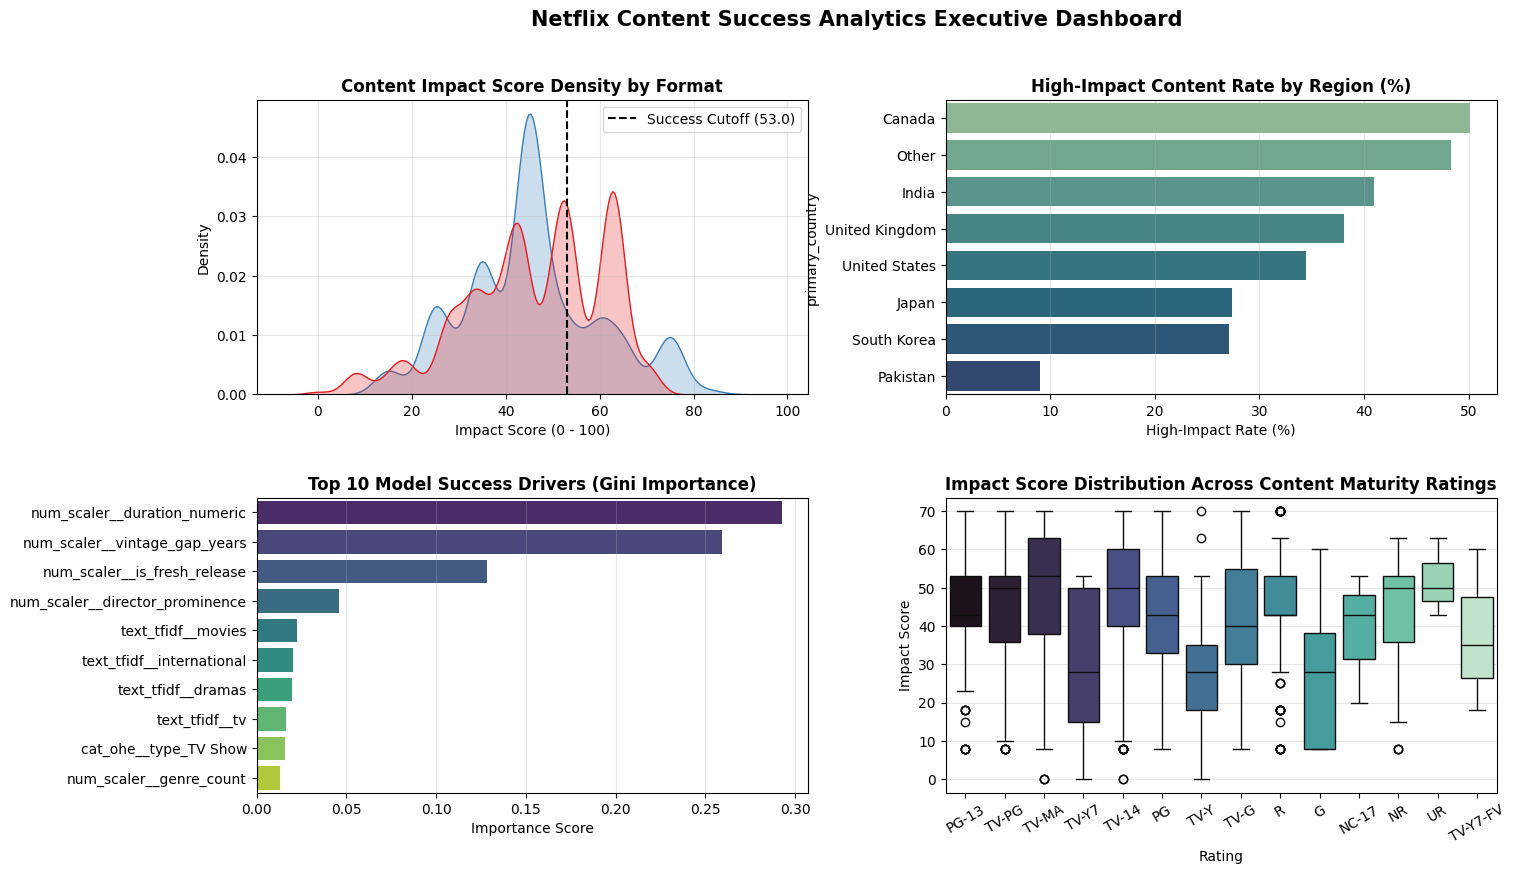

In [7]:
# Multi-Panel Executive Business Intelligence Dashboard
fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.25)

# Panel 1: Content Impact Score Distribution by Type
ax1 = fig.add_subplot(gs[0, 0])
sns.kdeplot(data=df_engine, x='content_impact_score', hue='type', fill=True, common_norm=False, palette='Set1', ax=ax1)
ax1.axvline(threshold, color='black', linestyle='--', linewidth=1.5, label=f'Success Cutoff ({threshold:.1f})')
ax1.set_title('Content Impact Score Density by Format', fontsize=12, fontweight='bold')
ax1.set_xlabel('Impact Score (0 - 100)', fontsize=10)
ax1.legend()
ax1.grid(alpha=0.3)

# Panel 2: Impact Rate by Primary Country
ax2 = fig.add_subplot(gs[0, 1])
country_impact = df_engine.groupby('primary_country')['is_high_impact'].mean().sort_values(ascending=False) * 100
sns.barplot(x=country_impact.values, y=country_impact.index, palette='crest', ax=ax2)
ax2.set_title('High-Impact Content Rate by Region (%)', fontsize=12, fontweight='bold')
ax2.set_xlabel('High-Impact Rate (%)', fontsize=10)
ax2.grid(axis='x', alpha=0.3)

# Panel 3: Feature Importances of Champion Random Forest Model
ax3 = fig.add_subplot(gs[1, 0])
rf_classifier = pipelines['Random Forest'].named_steps['classifier']
rf_preprocessor = pipelines['Random Forest'].named_steps['preprocessor']

try:
    all_cols = list(rf_preprocessor.get_feature_names_out())
except Exception:
    tfidf_cols = list(rf_preprocessor.named_transformers_['text_tfidf'].get_feature_names_out())
    cat_cols = list(rf_preprocessor.named_transformers_['cat_ohe'].get_feature_names_out())
    all_cols = tfidf_cols + cat_cols + numerical_features

importances = rf_classifier.feature_importances_
top_idx = np.argsort(importances)[::-1][:10]
top_feats = [all_cols[i] for i in top_idx]
top_vals = importances[top_idx]

sns.barplot(x=top_vals, y=top_feats, palette='viridis', ax=ax3)
ax3.set_title('Top 10 Model Success Drivers (Gini Importance)', fontsize=12, fontweight='bold')
ax3.set_xlabel('Importance Score', fontsize=10)
ax3.grid(axis='x', alpha=0.3)

# Panel 4: Movie Runtime vs. Impact Score Scatter / Boxplot
ax4 = fig.add_subplot(gs[1, 1])
movies_sub = df_engine[(df_engine['type'] == 'Movie') & (df_engine['duration_numeric'].between(50, 180))]
sns.boxplot(data=movies_sub, x='clean_rating', y='content_impact_score', palette='mako', ax=ax4)
ax4.set_title('Impact Score Distribution Across Content Maturity Ratings', fontsize=12, fontweight='bold')
ax4.set_xlabel('Rating', fontsize=10)
ax4.set_ylabel('Impact Score', fontsize=10)
ax4.tick_params(axis='x', rotation=30)
ax4.grid(axis='y', alpha=0.3)

plt.suptitle('Netflix Content Success Analytics Executive Dashboard', fontsize=15, fontweight='bold', y=0.98)
plt.show()

## **Interactive Pre-Release Content Scorer (Executive Simulator)**

Content acquisition managers and producers can evaluate hypothetical or upcoming titles below to predict their success probability and receive real-time optimization guidance:

In [8]:
#@title Pre-Release Title Evaluator
input_title = "Horizon Chronicles" #@param {type:"string"}
input_type = "TV Show" #@param ["Movie", "TV Show"]
input_genres = "International TV Shows, TV Dramas, TV Thrillers" #@param {type:"string"}
input_rating = "TV-MA" #@param ["TV-MA", "TV-14", "TV-PG", "R", "PG-13", "TV-Y7", "TV-G", "NR"]
input_country = "South Korea" #@param ["United States", "India", "United Kingdom", "Pakistan", "South Korea", "Japan", "Canada", "France", "Other"]
input_duration = 2 #@param {type:"integer"} {description: "Minutes for Movie, Seasons for TV Show"}
input_director_prominence = 3 #@param {type:"slider", min:0, max:10, step:1}
is_coproduction_flag = 1 #@param [0, 1] {type:"raw"}
vintage_lag_years = 0 #@param {type:"integer"} {description: "0 for new premiere release"}

# Construct query sample
query_df = pd.DataFrame([{
    'listed_in': input_genres,
    'type': input_type,
    'clean_rating': input_rating,
    'primary_country': input_country,
    'vintage_gap_years': vintage_lag_years,
    'duration_numeric': input_duration,
    'director_prominence': input_director_prominence,
    'genre_count': len([x for x in input_genres.split(',') if x.strip()]),
    'is_coproduction': is_coproduction_flag,
    'is_fresh_release': 1 if vintage_lag_years <= 1 else 0
}])

# Predict using Champion Pipeline (Random Forest)
champion_pipeline = pipelines['Random Forest']
pred_label = champion_pipeline.predict(query_df)[0]
pred_probs = champion_pipeline.predict_proba(query_df)[0]
success_prob = pred_probs[1] * 100

print("=" * 75)
print(f"EXECUTIVE PRE-RELEASE IMPACT ASSESSMENT: '{input_title.upper()}'")
print("=" * 75)
print(f"• Projected Classification    : {'HIGH-IMPACT SUCCESS POTENTIAL' if pred_label == 1 else 'STANDARD CATALOG ADDITION'}")
print(f"• Success Impact Probability   : {success_prob:.1f}%")
print(f"• Standard Risk Probability    : {pred_probs[0]*100:.1f}%")
print("-" * 75)
print("STRATEGIC RECOMMENDATION:")
if success_prob >= 70:
    print("★ STRONG BUY / ACQUIRE: High viewer engagement potential with favorable genre synergies")
    print("  and strong format characteristics. Recommend prime homepage carousel placement.")
elif success_prob >= 45:
    print("▲ MODERATE POTENTIAL: Viable catalog filler with targeted niche appeal.")
    print("  Consider pairing with targeted regional marketing campaigns.")
else:
    print("▼ CONSERVATIVE BID: Low expected retention score based on metadata profile.")
    print("  Recommend renegotiating acquisition license fees or tightening runtime window.")
print("=" * 75)

EXECUTIVE PRE-RELEASE IMPACT ASSESSMENT: 'HORIZON CHRONICLES'
• Projected Classification    : HIGH-IMPACT SUCCESS POTENTIAL
• Success Impact Probability   : 84.1%
• Standard Risk Probability    : 15.9%
---------------------------------------------------------------------------
STRATEGIC RECOMMENDATION:
★ STRONG BUY / ACQUIRE: High viewer engagement potential with favorable genre synergies
  and strong format characteristics. Recommend prime homepage carousel placement.


```markdown
## **Step 6: Model Serialization and Gradio Frontend Deployment**

To make this Content Success Analytics Engine accessible to stakeholders, we will:
1. **Serialize and save** the trained Champion Random Forest pipeline using `joblib`.
2. **Develop an interactive web frontend** using **Gradio** where team members can input metadata and instantly receive success scores alongside optimal strategy explanations.
```

In [9]:
# Install Gradio and joblib packages
!pip install -q gradio joblib

In [10]:
import joblib
import os

# Save the Champion Random Forest Pipeline to a model file
model_path = '/content/netflix_rf_champion_model.joblib'
joblib.dump(pipelines['Random Forest'], model_path)

print(f"✓ Champion Model saved successfully at: {model_path} ({os.path.getsize(model_path) / (1024 * 1024):.2f} MB)")

✓ Champion Model saved successfully at: /content/netflix_rf_champion_model.joblib (5.22 MB)


In [ ]:
import gradio as gr
import pandas as pd
import joblib

# Load the saved model to verify integrity
loaded_pipeline = joblib.load('/content/netflix_rf_champion_model.joblib')

def predict_content_success(title, media_type, genres, rating, country, duration, director_prominence, is_coproduction, vintage_gap):
    # Map visual string outputs to binary features expected by model pipeline
    is_coprod_numeric = 1 if str(is_coproduction).strip().lower() in ['yes', '1', '1.0'] else 0

    # Reconstruct robust input schema matching training format
    query_data = pd.DataFrame([{
        'listed_in': genres,
        'type': media_type,
        'clean_rating': rating,
        'primary_country': country,
        'vintage_gap_years': int(vintage_gap),
        'duration_numeric': int(duration),
        'director_prominence': int(director_prominence),
        'genre_count': len([g.strip() for g in genres.split(',') if g.strip()]),
        'is_coproduction': is_coprod_numeric,
        'is_fresh_release': 1 if int(vintage_gap) <= 1 else 0
    }])

    # Generate predictions using our pipeline
    pred_label = loaded_pipeline.predict(query_data)[0]
    probabilities = loaded_pipeline.predict_proba(query_data)[0]
    success_prob = float(probabilities[1]) * 100
    risk_prob = float(probabilities[0]) * 100

    # Construct Strategic Executive Recommendations
    if success_prob >= 70:
        recommendation = "★ STRONG BUY / ACQUIRE: High viewer engagement potential with favorable genre synergies and strong format characteristics. Recommend prime homepage carousel placement."
        status = "🔥 High-Impact Success Potential"
    elif success_prob >= 45:
        recommendation = "▲ MODERATE POTENTIAL: Viable catalog filler with targeted niche appeal. Consider pairing with targeted regional marketing campaigns."
        status = "⚖️ Standard Catalog Addition"
    else:
        recommendation = "▼ CONSERVATIVE BID: Low expected retention score based on metadata profile. Recommend renegotiating acquisition license fees or tightening runtime window."
        status = "⚠️ Conservative Catalog Risk"

    # Beautiful markdown report card return
    report_markdown = f"""
    ### Executive Assessment Report for **{title}**

    * **Format Classification:** {status}
    * **Success Probability:** `{success_prob:.1f}%`
    * **Catalog Risk Factor:** `{risk_prob:.1f}%`

    ---
    #### 📊 STRATEGIC RECOMMENDATION:
    *{recommendation}*
    """

    return report_markdown

# Build the custom web layout
with gr.Blocks(theme=gr.themes.Soft(primary_hue="red", secondary_hue="slate")) as app:
    gr.Markdown("# 🎬 Netflix Content Success Analytics Engine")
    gr.Markdown("### Enterprise Pre-Release Title Simulator & Decision-Support System")

    with gr.Row():
        with gr.Column(scale=1):
            gr.Markdown("### 🛠️ Input Title Metadata")
            title = gr.Textbox(value="Horizon Chronicles", label="Project Working Title")
            media_type = gr.Dropdown(choices=["Movie", "TV Show"], value="TV Show", label="Content Format")
            genres = gr.Textbox(value="International TV Shows, TV Dramas, TV Thrillers", label="Associated Genres (Comma-separated)")
            rating = gr.Dropdown(choices=["TV-MA", "TV-14", "TV-PG", "R", "PG-13", "TV-Y7", "TV-G", "NR", "Unknown"], value="TV-MA", label="Maturity Rating")
            country = gr.Dropdown(choices=["United States", "India", "United Kingdom", "Pakistan", "South Korea", "Japan", "Canada", "France", "Other"], value="South Korea", label="Primary Country")
            duration = gr.Slider(minimum=1, maximum=240, step=1, value=2, label="Duration (Minutes for Movies, Seasons for TV Shows)")
            director_prominence = gr.Slider(minimum=0, maximum=15, step=1, value=3, label="Director Catalog Prominence (Historical Count)")
            is_coproduction = gr.Radio(choices=["Yes", "No"], value="Yes", label="Multi-Country Co-production")
            vintage_gap = gr.Number(value=0, label="Vintage Gap Years (0 for New Premiere Release)")

            submit_btn = gr.Button("🚀 Run Executive Assessment Pipeline", variant="primary")

        with gr.Column(scale=1):
            gr.Markdown("### 📊 Real-Time AI Business Intelligence Engine Output")
            output_report = gr.Markdown("*Fill out the metadata on the left and click submit to run the champion model pipeline.*")

    submit_btn.click(
        fn=predict_content_success,
        inputs=[title, media_type, genres, rating, country, duration, director_prominence, is_coproduction, vintage_gap],
        outputs=output_report
    )

# Launch application with external share link and debug tools activated
app.launch(share=True, inline=False, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://d7bdb89f8a2109008e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
